<h1>IMPORTAÇÃO DE BIBLIOTECAS</h1>

In [8]:
import pandas as pd
import numpy as np

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

import seaborn as sns

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

<h1>Criação de Pipelines </h1>

In [ ]:
preprocessing_path = "./preprocessing/"

preprocessing_dataset_fileName = "05-preprocessing_dataset.csv"
ml_classification_dataset_filename = "06-ml_models_dataset.csv"
dense_classification_dataset_filename = "06-dense_modles_dataset.csv"

df_dataset = pd.read_csv(preprocessing_path+preprocessing_dataset_fileName)
df_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 13830 entries, 0 to 13829
Data columns (total 35 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   dataName              13830 non-null  str    
 1   motorSpeed            13830 non-null  float64
 2   load                  13830 non-null  float64
 3   class                 13830 non-null  str    
 4   rawData               13830 non-null  str    
 5   I_energy              13830 non-null  float64
 6   I_kurtosis            13830 non-null  float64
 7   I_max                 13830 non-null  float64
 8   I_mode                13830 non-null  float64
 9   I_skewness            13830 non-null  float64
 10  Q_energy              13830 non-null  float64
 11  Q_kurtosis            13830 non-null  float64
 12  Q_max                 13830 non-null  float64
 13  Q_median              13830 non-null  float64
 14  Q_min                 13830 non-null  float64
 15  Q_mode                13830 no

In [43]:
data_numeric = df_dataset.select_dtypes(include="number")

pipeline_preprocessamento_class = LabelEncoder()
data_class = pipeline_preprocessamento_class.fit_transform(df_dataset['class'])

pipeline_preprocessamento_features = ColumnTransformer([
    ("scaler", StandardScaler(), data_numeric.columns)
], remainder="drop")

pipeline_machineLearning = Pipeline([
    ("preprocessamento", pipeline_preprocessamento_features),
    ("modelo", GaussianNB())
])

param_grid = [
    {
        "modelo": [GaussianNB()]
    },
    {
        "modelo":[DecisionTreeClassifier(random_state=0)],
        "modelo__criterion": ['gini', 'entropy'],
        "modelo__max_depth": [3,6,9]
    },
    {
        "modelo":[RandomForestClassifier(random_state=0)],
        "modelo__n_estimators": [10, 20, 30],
        "modelo__max_depth": [3,6,9],
        "modelo__min_samples_split": [2, 5, 10],
        "modelo__min_samples_leaf": [1, 2, 4]
    },
    {
        "modelo":[KNeighborsClassifier()],
        "modelo__n_neighbors":[3,5,7,10]
    }
]

grid_search = GridSearchCV(
    pipeline_machineLearning,
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)


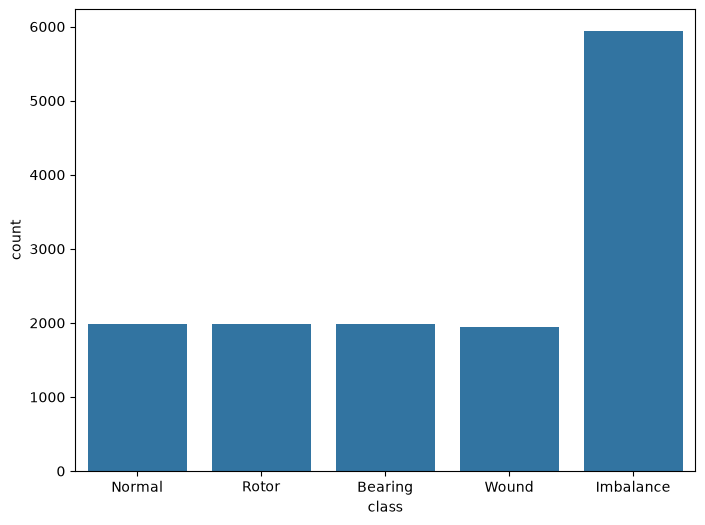

In [44]:
%matplotlib inline
plt.rcParams['figure.figsize'] = [8, 6]
sns.countplot(data=df_dataset, x="class")
plt.show()

In [45]:
X_train, X_test, y_train, y_test = train_test_split(data_numeric, data_class, test_size=0.7, random_state=0, stratify=data_class)
grid_search.fit(X_train, y_train)
print(f'Melhor pontuação: {grid_search.best_score_*100}%')
print(f'Melhor modelo: {grid_search.best_params_}')
print(f'Melhores parâmetros: {grid_search.best_params_}')
ml_results = pd.DataFrame(grid_search.cv_results_)

ml_results.to_csv(preprocessing_path+ml_classification_dataset_filename, index=False)
ml_results.head()

Melhor pontuação: 99.73488162541602%
Melhor modelo: {'modelo': KNeighborsClassifier(), 'modelo__n_neighbors': 3}
Melhores parâmetros: {'modelo': KNeighborsClassifier(), 'modelo__n_neighbors': 3}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_modelo,param_modelo__criterion,param_modelo__max_depth,param_modelo__min_samples_leaf,param_modelo__min_samples_split,param_modelo__n_estimators,param_modelo__n_neighbors,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.162213,0.036973,0.020277,0.006165,GaussianNB(),NaN,NaN,NaN,NaN,NaN,NaN,{'modelo': GaussianNB()},0.914458,0.900000,0.910843,0.890361,0.916767,0.906486,0.009903,63
1,0.246235,0.055947,0.016993,0.005529,DecisionTreeClassifier(random_state=0),gini,3.0,NaN,NaN,NaN,NaN,{'modelo': DecisionTreeClassifier(random_state...,0.826506,0.862651,0.839759,0.833735,0.838359,0.840202,0.012140,92
2,0.186604,0.069450,0.015898,0.002466,DecisionTreeClassifier(random_state=0),gini,6.0,NaN,NaN,NaN,NaN,{'modelo': DecisionTreeClassifier(random_state...,0.938554,0.966265,0.965060,0.957831,0.955368,0.956616,0.009937,62
3,0.188958,0.023267,0.013815,0.001726,DecisionTreeClassifier(random_state=0),gini,9.0,NaN,NaN,NaN,NaN,{'modelo': DecisionTreeClassifier(random_state...,0.975904,0.980723,0.978313,0.983133,0.975875,0.978789,0.002816,44
4,0.178859,0.037462,0.021193,0.019637,DecisionTreeClassifier(random_state=0),entropy,3.0,NaN,NaN,NaN,NaN,{'modelo': DecisionTreeClassifier(random_state...,0.893976,0.904819,0.896386,0.885542,0.862485,0.888642,0.014449,82


In [46]:
y_pred = grid_search.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.99      0.99      1386
           1       1.00      1.00      1.00      4158
           2       1.00      1.00      1.00      1386
           3       1.00      1.00      1.00      1386
           4       1.00      1.00      1.00      1365

    accuracy                           1.00      9681
   macro avg       1.00      1.00      1.00      9681
weighted avg       1.00      1.00      1.00      9681



In [47]:
model = grid_search.best_estimator_
x = df_dataset.drop(columns=['class'])
y = pipeline_preprocessamento_class.transform(df_dataset['class'])

y_pred = model.predict(x)
results = pd.DataFrame({"y Real": pipeline_preprocessamento_class.inverse_transform(y), "y Predi": pipeline_preprocessamento_class.inverse_transform(y_pred)})
results[results["y Real"] != results["y Predi"]]

,y Real,y Predi
2405,Rotor,Imbalance
2610,Rotor,Imbalance
2633,Rotor,Imbalance
2640,Rotor,Imbalance
3361,Rotor,Imbalance
3414,Rotor,Imbalance
3715,Rotor,Imbalance
4231,Bearing,Imbalance
4232,Bearing,Imbalance
4233,Bearing,Imbalance


<h2>Rede Neural</h2>

In [21]:
import tensorflow as tf
from tensorflow import keras

In [ ]:
dense_preprocessor_x= StandardScaler()
dense_encoder_y = OneHotEncoder(sparse_output=False)

X_train, X_test, y_train, y_test = train_test_split(data_numeric, data_class, test_size=0.7, random_state=0, stratify=data_class)
X_train = dense_preprocessor_x.fit_transform(X_train)
X_test = dense_preprocessor_x.transform(X_test)

y_dense_train = dense_encoder.fit_transform(y_train.reshape(-1, 1))
y_dense_test = dense_encoder.transform(y_test.reshape(-1, 1))

num_class = len(dense_encoder.categories_[0])
num_features = data_numeric.shape[1]

print(f'Classes: {num_class}; Features: {num_features}')
data_numeric.describe()



Classes: 5; Features: 32


,motorSpeed,load,I_energy,I_kurtosis,I_max,I_mode,I_skewness,Q_energy,Q_kurtosis,Q_max,...,fase_mean,fase_median,fase_mode,fase_rms,fase_skewness,fase_std,fft_bandwidth,fft_frequency_mean,fft_frequency_median,fft_kurtosis
count,13830.000000,13830.000000,13830.000000,13830.000000,13830.000000,13830.000000,13830.000000,13830.000000,13830.000000,13830.000000,...,13830.000000,13830.000000,13830.000000,13830.000000,13830.000000,13830.000000,13830.000000,13830.000000,13830.000000,13830.000000
mean,1000.650759,1.247289,74500.364166,2.756399,4.856370,2.568327,0.059032,71647.050290,2.981233,4.625819,...,0.788819,0.782518,0.476168,0.821749,-0.315582,0.226961,818.294275,464.191280,163.530098,4614.804895
std,316.272827,0.852880,4193.459151,0.362579,0.383192,1.178642,0.284410,4029.796051,0.472979,0.453228,...,0.011282,0.012777,0.623110,0.012235,1.039792,0.039351,66.281220,71.820979,48.155937,106.483383
min,500.000000,0.000000,2322.016955,1.773020,0.488293,-0.001887,-1.346414,2260.310531,1.083367,0.479195,...,0.510536,0.591409,-1.570407,0.673752,-4.318759,0.002899,606.211482,247.490687,0.000000,3211.640088
25%,700.000000,0.500000,72809.132942,2.484575,4.613975,2.188605,-0.108502,70163.995048,2.611241,4.253640,...,0.780097,0.774582,0.474945,0.811606,-0.272983,0.203941,774.562968,416.536086,127.987201,4564.007000
50%,1000.000000,1.000000,74579.764132,2.625663,4.935655,2.525604,0.091734,71210.171211,2.830103,4.646917,...,0.789922,0.781204,0.621315,0.823403,0.036339,0.219076,816.254213,465.968256,164.983502,4617.197488
75%,1300.000000,2.000000,76344.748267,2.956872,5.185851,2.842178,0.300306,72786.825897,3.360099,5.019765,...,0.795910,0.790110,0.725403,0.830344,0.267949,0.247252,859.034426,511.812958,199.980002,4707.122289
max,1500.000000,2.500000,99593.855272,3.842892,5.196064,5.185851,0.665892,127176.207168,5.390342,5.193420,...,0.846178,0.900452,1.569502,0.953277,0.725685,0.792183,1203.729567,738.272902,346.000000,4998.975496


In [ ]:
model = keras.Sequential([
    keras.layers.Dense(num_features, activation="relu", input_shape=(num_features,)), #INPUT
    
    #keras.layers.Dense(2*num_features, activation="relu"),
    #keras.layers.Dense(int((num_features+num_class)/2), activation="relu"),
    #keras.layers.Dense(2*num_class, activation="relu"),
    
    keras.layers.Dense(num_class, activation="softmax") #OUTPUT
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

d:\MBA_IA_BIG_DATA\TCC\.venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_55 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_56 (Dense)                │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,221 (4.77 KB)

 Trainable params: 1,221 (4.77 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
130/130 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6823 - loss: 0.9338
Epoch 2/10
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9325 - loss: 0.3072
Epoch 3/10
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9610 - loss: 0.1682
Epoch 4/10
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9761 - loss: 0.1123
Epoch 5/10
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9848 - loss: 0.0822
Epoch 6/10
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9870 - loss: 0.0636
Epoch 7/10
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9906 - loss: 0.0510
Epoch 8/10
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9930 - loss: 0.0419
Epoch 9/10
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9942 - loss: 0.0353
Epoch 10/10
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9949 - loss: 0.0299
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9957 - loss: 0.0264
Acurácia: 99.57%


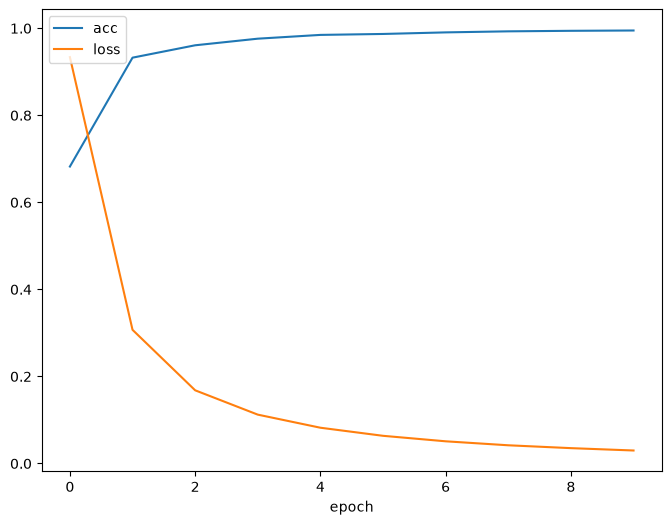

In [66]:
%matplotlib inline
history = model.fit(X_train, y_dense_train, epochs=10)

test_loss, test_acc = model.evaluate(X_train, y_dense_train)
print(f'Acurácia: {test_acc*100:.02f}%')

# Mostrar graficamente
plt.plot(history.history['accuracy'])
plt.plot(history.history['loss'])
plt.xlabel('epoch')
plt.legend(['acc', 'loss'], loc='upper left')
plt.show()

In [67]:
y_pred_prob = model.predict(X_train)

y_pred_index = np.argmax(y_pred_prob, axis=1)

y_pred = dense_encoder.categories_[0][y_pred_index]

results = {
    "y_pred": y_pred,
    "y": y_train
}

df_result = pd.DataFrame(results)
df_result['test'] = df_result['y_pred'] == df_result['y']


130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


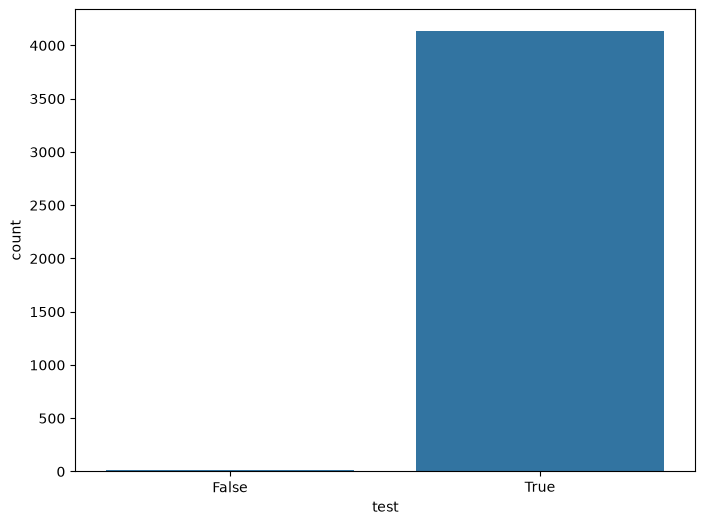

In [68]:
%matplotlib inline

plt.rcParams['figure.figsize'] = [8, 6]
sns.countplot(data=df_result, x="test")
plt.show()

In [69]:
df_erros = df_result[df_result['test'] == False]
df_erros.value_counts()

y_pred  y  test 
1       3  False    8
        0  False    7
0       1  False    2
3       1  False    1
Name: count, dtype: int64